CapyMOA is a Python wrapper for MOA (Massive Online Analysis), which is written in Java. To use CapyMOA, a Java Development Kit (JDK) needs to be installed and properly configured. The following cell installs `openjdk-17-jdk` and sets the `JAVA_HOME` environment variable, which is required by CapyMOA.

In [ ]:
import os, glob, subprocess

# Install OpenJDK 17 (headless)
!apt-get update -qq > /dev/null
!apt-get install -y openjdk-17-jdk-headless -qq > /dev/null

# Set JAVA_HOME to whichever JDK actually exists (avoids a wrong hard-coded path)
candidates = sorted(glob.glob("/usr/lib/jvm/java-17-openjdk-*")) or sorted(glob.glob("/usr/lib/jvm/*openjdk*"))
if candidates:
    os.environ["JAVA_HOME"] = candidates[0]
print("JAVA_HOME =", os.environ.get("JAVA_HOME"))

!java -version

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
JAVA_HOME = /usr/lib/jvm/java-17-openjdk-amd64
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12" 2026-07-21
OpenJDK Runtime Environment (build 21.0.12+8-1-24.04-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12+8-1-24.04-Ubuntu, mixed mode, sharing)


# Approach 2: Conditional Gated Training (CGT)

This approach focuses on reducing computational cost by avoiding running all models all the time.

The key idea is simple: only use expensive models when they are actually needed.

* The Hoeffding Tree is always active since it is fast and low-cost. It acts as the main baseline model.
* An ADWIN detector continuously monitors the error of the Hoeffding Tree.
* When a change in data (drift) is detected, we activate the more powerful models like Adaptive Random Forest (ARF) and KNN-ADWIN.
* Once the drift is over (no more change detected), we turn off the expensive models and go back to using only the Hoeffding Tree.

This “on-demand” activation is called conditional gating.

By doing this, we avoid unnecessary computation and significantly reduce cost. In fact, this approach aims to use only about 30% of the computational cost compared to running all models continuously in shadow mode.

In [ ]:
import subprocess, sys, importlib.metadata as md

# IMPORTANT: do NOT pip-install numpy / scipy / pandas / matplotlib etc. one by one.
# Colab already ships compatible versions; re-installing them while numpy is loaded
# corrupts the running kernel ("numpy.ufunc has no attribute __module__").
import numpy as _np
numpy_before = _np.__version__

print("Installing dependencies...")
result = subprocess.run(
    [sys.executable, "-m", "pip", "install", "--quiet",
     "capymoa", "loguru", "collections-extended", "psutil"],
    capture_output=True, text=True
)
if result.returncode != 0:
    print("pip error:\n", result.stderr[-2000:])
else:
    print("Dependencies installed.")

numpy_after = md.version("numpy")
if numpy_after != numpy_before:
    print(f"\n⚠️  numpy changed ({numpy_before} -> {numpy_after}) during install.")
    print("   Go to Runtime -> Restart session, then run the notebook again from the top")
    print("   (this cell will then finish instantly and everything will import cleanly).")
else:
    print("numpy unchanged - no restart needed.")

Installing dependencies...
Dependencies installed.
numpy unchanged - no restart needed.


In [ ]:
import subprocess, sys, os, signal, importlib.metadata as md

# Do NOT import numpy/pandas/etc. in this cell: installing capymoa can change the numpy
# version on disk, and a kernel that already loaded the old one becomes corrupted.
def ver(pkg):
    try:
        return md.version(pkg)
    except Exception:
        return None

watched = ["numpy", "scipy", "pandas", "scikit-learn", "matplotlib", "seaborn"]
before = {p: ver(p) for p in watched}

print("Installing dependencies...")
r = subprocess.run(
    [sys.executable, "-m", "pip", "install", "--quiet",
     "capymoa", "loguru", "collections-extended", "psutil"],
    capture_output=True, text=True)
if r.returncode != 0:
    print("pip error:\n", r.stderr[-2000:])

after = {p: ver(p) for p in watched}
changed = {p: (before[p], after[p]) for p in watched if before[p] != after[p]}

if changed:
    print("Package versions changed:", changed)
    print("Restarting the kernel automatically. After it restarts, run the notebook again")
    print("from the top (this cell will then finish instantly with no changes).")
    os.kill(os.getpid(), signal.SIGKILL)   # forces a clean restart
else:
    print("Dependencies OK - no restart needed.")

Installing dependencies...
Dependencies OK - no restart needed.


In [ ]:
#  Import all modules & configure CGT system

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
from collections import deque
from tqdm.notebook import tqdm

# Logging
from loguru import logger
logger.remove()
logger.add(lambda msg: print(msg, end=""), level="INFO")

warnings.filterwarnings('ignore')
np.random.seed(42)
rng = np.random.default_rng(42)

#  Directory
OUTPUT_DIR = 'project_outputs'
os.makedirs(OUTPUT_DIR, exist_ok=True)


#  CapyMOA (SAFE IMPORT WITH FALLBACK)
CAPYMOA_AVAILABLE = False

class SimpleADWIN:
    """Lightweight pure-Python ADWIN-style detector (fallback if CapyMOA/Java is unavailable).
    Same API as capymoa's ADWIN: add_element(value) / detected_change()."""
    def __init__(self, delta=0.002, max_window=500, check_every=16, min_side=30):
        self.delta, self.max_window = delta, max_window
        self.check_every, self.min_side = check_every, min_side
        self.win = deque(maxlen=max_window)
        self._n = 0
        self._change = False

    def add_element(self, v):
        self.win.append(float(v))
        self._n += 1
        self._change = False
        if self._n % self.check_every or len(self.win) < 2 * self.min_side:
            return
        arr = np.array(self.win)
        n = len(arr)
        csum = np.cumsum(arr)
        for cut in range(self.min_side, n - self.min_side + 1, 10):
            n0, n1 = cut, n - cut
            m0 = csum[cut - 1] / n0
            m1 = (csum[-1] - csum[cut - 1]) / n1
            m = 1.0 / (1.0 / n0 + 1.0 / n1)
            eps = np.sqrt((1.0 / (2 * m)) * np.log(4.0 * n / self.delta))
            if abs(m0 - m1) > eps:
                for _ in range(cut):          # drop the stale part of the window
                    self.win.popleft()
                self._change = True
                return

    def detected_change(self):
        return self._change

try:
    import capymoa
    from capymoa.drift.detectors import ADWIN
    CAPYMOA_AVAILABLE = True
except Exception as e:
    print(f"CapyMOA import failed ({type(e).__name__}: {e}) -> using SimpleADWIN fallback")
    ADWIN = SimpleADWIN


# Light vs Heavy separation
LIGHT_MODELS = ['HoeffdingTree']
HEAVY_MODELS = ['AdaptiveRF', 'KNN_ADWIN']

# Drift + Warmup control
WARMUP_PROB = 0.05
DRIFT_COOLDOWN = 200

# Runtime state
in_drift = False
drift_timer = 0

#  Model Costs (
MODEL_COST = {
    'HoeffdingTree': 1,
    'NaiveBayes': 1,
    'AdaptiveRF': 5,
    'KNN_ADWIN': 2
}



def init_tracking(models):
    return {
        m: {
            "acc_window": deque(maxlen=50),
            "usage_count": 0
        }
        for m in models
    }



def should_activate_heavy(drift_signal):
    """
    Core CGT decision function
    """

    global in_drift, drift_timer

    # If drift detected → activate heavy models
    if drift_signal:
        in_drift = True
        drift_timer = DRIFT_COOLDOWN
        logger.info(" Drift detected → Activating heavy models\n")

    # Maintain active period after drift
    if in_drift:
        drift_timer -= 1
        if drift_timer <= 0:
            in_drift = False
            logger.info(" Drift stabilized → Deactivating heavy models\n")
        return True

    # Stochastic warm-up (prevents cold start)
    if rng.random() < WARMUP_PROB:
        return True

    return False


#  Plot Config ─
plt.rcParams.update({
    'figure.dpi': 130,
    'axes.grid': True,
    'grid.alpha': 0.3,
})

#  Colors ─
COLORS = {
    'HoeffdingTree':  '#1565C0',
    'AdaptiveRF':     '#E53935',
    'NaiveBayes':     '#2E7D32',
    'KNN_ADWIN':      '#6A1B9A',
    'CGT_System':     '#E65100',
}

MODEL_ORDER = ['HoeffdingTree', 'AdaptiveRF', 'NaiveBayes', 'CGT_System']

In [ ]:

#  Stream Generators


class BaseStream:
    def __init__(self):
        self.idx = 0

    def has_more_instances(self):
        return self.idx < self.n_instances

    def next_instance(self):
        x = self.X[self.idx]
        y = self.y[self.idx]


        drift_flag = self.idx in getattr(self, "drift_points", [])

        self.idx += 1
        return x, y, drift_flag

    def reset(self):
        self.idx = 0


# 1. SEA Abrupt Drift → Adaptation Speed

class CapyMOA_SEA_AbruptStream(BaseStream):
    def __init__(self, n_instances=8000, drift_point=4000, noise=0.1, seed=42):
        super().__init__()
        self.n_instances = n_instances
        self.drift_point = drift_point
        self.name = f'SEA_AbruptDrift@{drift_point}'

        rng = np.random.default_rng(seed)
        X = rng.uniform(0, 10, (n_instances, 3))
        y = np.zeros(n_instances, dtype=int)

        for i in range(n_instances):
            thresh = 8.0 if i < drift_point else 9.0
            label = int((X[i, 0] + X[i, 1]) <= thresh)
            if rng.random() < noise:
                label = 1 - label
            y[i] = label

        self.X, self.y = X, y
        self.drift_points = [drift_point]




# 2. Gradual Drift → Stability

class CapyMOA_Hyperplane_GradualStream(BaseStream):
    def __init__(self, n_instances=8000, drift_point=4000, transition_width=1000, noise=0.05, seed=42):
        super().__init__()
        self.n_instances = n_instances
        self.drift_point = drift_point
        self.name = f'Hyperplane_GradualDrift@{drift_point}'

        rng = np.random.default_rng(seed)
        X = rng.uniform(0, 1, (n_instances, 4))

        w_s = np.array([0.6, 0.2, 0.8, 0.1])
        w_e = np.array([0.1, 0.9, 0.3, 0.7])

        y = np.zeros(n_instances, dtype=int)

        for i in range(n_instances):
            alpha = np.clip((i - drift_point) / transition_width, 0.0, 1.0)
            w = (1 - alpha) * w_s + alpha * w_e

            label = int(np.dot(X[i], w) >= np.dot(w, np.ones(4)) / 2)
            if rng.random() < noise:
                label = 1 - label

            y[i] = label

        self.X, self.y = X, y

        self.drift_points = list(range(drift_point, drift_point + transition_width))

        print(f'  [] {self.name} generated. Focus: Stability-Plasticity.')


# 3. Recurring Drift → Memory

class CapyMOA_RotatingHyperplane_RecurringStream(BaseStream):
    def __init__(self, n_instances=8000, drift_points=None, noise=0.05, seed=42):
        super().__init__()

        if drift_points is None:
            drift_points = [2500, 5000]

        self.n_instances = n_instances
        self.name = 'RotHyperplane_Recurring'

        rng = np.random.default_rng(seed)
        X = rng.uniform(0, 1, (n_instances, 4))

        concepts = [
            np.array([0.7, 0.3, 0.2, 0.8]),
            np.array([0.1, 0.9, 0.6, 0.2]),
            np.array([0.7, 0.3, 0.2, 0.8])
        ]

        bounds = [0] + drift_points + [n_instances]
        y = np.zeros(n_instances, dtype=int)

        for seg, (s, e) in enumerate(zip(bounds[:-1], bounds[1:])):
            w = concepts[min(seg, 2)]
            for i in range(s, e):
                label = int(np.dot(X[i], w) >= np.dot(w, np.ones(4)) / 2)
                if rng.random() < noise:
                    label = 1 - label
                y[i] = label

        self.X, self.y = X, y
        self.drift_points = drift_points


# Stream Factory

def get_stream(stream_type="SEA"):
    if stream_type == "SEA":
        return CapyMOA_SEA_AbruptStream()
    elif stream_type == "Gradual":
        return CapyMOA_Hyperplane_GradualStream()
    elif stream_type == "Recurring":
        return CapyMOA_RotatingHyperplane_RecurringStream()
    else:
        raise ValueError("Unknown stream type")




In [ ]:

#  Online Learner Pool (CGT CONTROLLED)


from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from collections import deque


# BASE MODEL INTERFACE (WITH GATING)

class BaseLearner:
    def __init__(self):
        self.training_enabled = True

    def predict(self, x):
        raise NotImplementedError

    def learn(self, x, y):
        if not self.training_enabled:
            return
        self._learn(x, y)

    def _learn(self, x, y):
        raise NotImplementedError



# HOEFFDING TREE (ALWAYS ON)

class CapyMOA_HoeffdingTree(BaseLearner):
    def __init__(self, grace_period=200, window_size=600):
        super().__init__()
        self.model = DecisionTreeClassifier(max_depth=8, min_samples_split=grace_period)
        self.X_buf, self.y_buf = [], []
        self.grace_period = grace_period
        self.window_size = window_size
        self.fitted = False
        self._n = 0
        self.name = 'HoeffdingTree'

    def predict(self, x):
        if not self.fitted:
            return 0
        return int(self.model.predict(x.reshape(1, -1))[0])

    def _learn(self, x, y):
        self.X_buf.append(x)
        self.y_buf.append(y)

        if len(self.X_buf) > self.window_size:
            self.X_buf.pop(0)
            self.y_buf.pop(0)

        self._n += 1

        if self._n % self.grace_period == 0 and len(self.X_buf) >= self.grace_period:
            self.model.fit(np.array(self.X_buf), np.array(self.y_buf))
            self.fitted = True



# ADAPTIVE RANDOM FOREST (HEAVY)

class CapyMOA_AdaptiveRandomForest(BaseLearner):
    def __init__(self, n_estimators=10, window=300, delta=0.002):
        super().__init__()
        self.trees = [DecisionTreeClassifier(max_depth=5, max_features='sqrt') for _ in range(n_estimators)]
        self.X_bufs = [[] for _ in range(n_estimators)]
        self.y_bufs = [[] for _ in range(n_estimators)]
        self.err_win = [deque(maxlen=250) for _ in range(n_estimators)]
        self.fitted = [False] * n_estimators

        self.window = window
        self.delta = delta
        self.name = 'AdaptiveRF'

    def predict(self, x):
        votes = []
        for i, t in enumerate(self.trees):
            if self.fitted[i]:
                votes.append(int(t.predict(x.reshape(1, -1))[0]))
        return int(np.round(np.mean(votes))) if votes else 0

    def _learn(self, x, y):
        for i in range(len(self.trees)):
            for _ in range(np.random.poisson(1.0)):
                self.X_bufs[i].append(x)
                self.y_bufs[i].append(y)

            if len(self.X_bufs[i]) > self.window:
                self.X_bufs[i] = self.X_bufs[i][-self.window:]
                self.y_bufs[i] = self.y_bufs[i][-self.window:]

            if len(self.X_bufs[i]) >= 60:
                self.trees[i].fit(np.array(self.X_bufs[i]), np.array(self.y_bufs[i]))
                self.fitted[i] = True



# NAIVE BAYES (LIGHT AUXILIARY)

class CapyMOA_NaiveBayes(BaseLearner):
    def __init__(self):
        super().__init__()
        self.model = GaussianNB()
        self.fitted = False
        self.name = 'NaiveBayes'

    def predict(self, x):
        if not self.fitted:
            return 0
        return int(self.model.predict(x.reshape(1, -1))[0])

    def _learn(self, x, y):
        self.model.partial_fit(x.reshape(1, -1), [y], classes=[0,1])
        self.fitted = True


# KNN (HEAVY)

class CapyMOA_KNN_ADWIN(BaseLearner):
    def __init__(self, k=5, max_window=700):
        super().__init__()
        self.k = k
        self.max_window = max_window
        self.X_win = []
        self.y_win = []
        self.name = 'KNN_ADWIN'

    def predict(self, x):
        if len(self.X_win) < self.k:
            return 0

        dists = np.linalg.norm(np.array(self.X_win) - x, axis=1)
        idx = np.argsort(dists)[:self.k]
        return int(np.round(np.mean([self.y_win[i] for i in idx])))

    def _learn(self, x, y):
        self.X_win.append(x)
        self.y_win.append(y)

        if len(self.X_win) > self.max_window:
            self.X_win.pop(0)
            self.y_win.pop(0)



# MODEL POOL FACTORY (CGT TAGGED)

def make_learner_pool():
    models = {
        'HoeffdingTree': CapyMOA_HoeffdingTree(),
        'AdaptiveRF': CapyMOA_AdaptiveRandomForest(),
        'NaiveBayes': CapyMOA_NaiveBayes(),
        'KNN_ADWIN': CapyMOA_KNN_ADWIN(),
    }

    for name, model in models.items():
        model.is_light = (name == 'HoeffdingTree')
        model.is_heavy = not model.is_light

    return models


In [ ]:

#   Prequential Evaluator (CGT OPTIMIZED)


class PrequentialEvaluator:
    """
    Test-then-train evaluator with CGT support:
    - accuracy tracking
    - cost tracking (light vs heavy)
    - gating statistics
    """

    def __init__(self, window_size=200):
        self.window_size = window_size

        # accuracy tracking
        self._win = deque(maxlen=window_size)
        self._all = []

        # cost tracking
        self._total_cost = []
        self._light_cost = []
        self._heavy_cost = []

        self._heavy_active = []

        # kappa stats
        self._kappa_counts = {'tp':0, 'tn':0, 'fp':0, 'fn':0}

    def update(self, y_true, y_pred, light_cost=0, heavy_cost=0, heavy_active=False):
        correct = int(y_true == y_pred)

        # accuracy
        self._win.append(correct)
        self._all.append(correct)

        # cost tracking
        total = light_cost + heavy_cost
        self._total_cost.append(total)
        self._light_cost.append(light_cost)
        self._heavy_cost.append(heavy_cost)

        # gating tracking
        self._heavy_active.append(int(heavy_active))

        # kappa tracking
        k = ('tp' if y_true==1 and y_pred==1 else
             'tn' if y_true==0 and y_pred==0 else
             'fp' if y_true==0 and y_pred==1 else 'fn')
        self._kappa_counts[k] += 1


    # ACCURACY

    def windowed_accuracy(self):
        return np.mean(self._win) if self._win else 0.0

    def cumulative_accuracy(self):
        return np.mean(self._all) if self._all else 0.0


    # COST ANALYSIS ( IMPORTANT)

    def mean_total_cost(self):
        return np.mean(self._total_cost) if self._total_cost else 0.0

    def mean_light_cost(self):
        return np.mean(self._light_cost) if self._light_cost else 0.0

    def mean_heavy_cost(self):
        return np.mean(self._heavy_cost) if self._heavy_cost else 0.0

    def heavy_activation_ratio(self):
        """Should be ~0.2 (20%) in CGT"""
        return np.mean(self._heavy_active) if self._heavy_active else 0.0


    # KAPPA

    def kappa(self):
        c = self._kappa_counts
        n = sum(c.values())
        if n == 0:
            return 0.0

        po = (c['tp'] + c['tn']) / n
        pe = (((c['tp']+c['fp'])*(c['tp']+c['fn']) +
               (c['tn']+c['fn'])*(c['tn']+c['fp'])) / (n*n))

        return (po - pe) / (1 - pe) if pe < 1 else 0.0


    # HISTORY

    def full_history(self):
        return np.array(self._all, dtype=float)



# SMOOTHING

from scipy.ndimage import uniform_filter1d

def smooth(arr, w=150):
    return uniform_filter1d(np.array(arr, dtype=float), size=w, mode='nearest')



In [ ]:

#  BehaviouralSensorSuite (CGT VERSION)


class BehaviouralSensorSuite:
    """
    Global sensor system for CGT:
    - Tracks overall system accuracy
    - Works with ADWIN for drift detection
    - Provides stability signals (optional)
    """

    def __init__(self, window_size=200):
        self.acc_window = deque(maxlen=window_size)
        self.error_window = deque(maxlen=window_size)


    # UPDATE (GLOBAL, NOT PER MODEL)

    def update(self, correct):
        error = 1 - int(correct)

        self.acc_window.append(correct)
        self.error_window.append(error)


    # SIGNALS (FOR ANALYSIS / DEBUG)

    def get_accuracy(self):
        return np.mean(self.acc_window) if self.acc_window else 0.0

    def get_stability(self):
        if len(self.acc_window) < 2:
            return 1.0
        return 1.0 - np.var(self.acc_window)

    def get_error_trend(self):
        if len(self.error_window) < 2:
            return 0.0

        arr = np.array(self.error_window)
        return float((arr[-1] - arr[0]) / (len(arr) + 1e-8))



In [ ]:

#   CGTController (FINAL SYSTEM)


class CGTController:
    """
    Conditional Gated Training system:
    - HT always active
    - Heavy models (ARF, KNN) activated only on drift/warmup
    """

    def __init__(self):
        #  Models
        self.ht  = CapyMOA_HoeffdingTree()
        self.arf = CapyMOA_AdaptiveRandomForest()
        self.nb  = CapyMOA_NaiveBayes()
        self.knn = CapyMOA_KNN_ADWIN()

        #  Drift Detector
        self.adwin = ADWIN()

        #  CGT State ─
        self.in_drift = False
        self.drift_timer = 0
        self.DRIFT_COOLDOWN = 200
        self.WARMUP_PROB = 0.05

        #  Tracking
        self.t = 1
        self.history = {
            "correct": [],
            "heavy_active": [],
        }


    # GATING LOGIC

    def _should_activate_heavy(self, drift_signal):
        if drift_signal:
            self.in_drift = True
            self.drift_timer = self.DRIFT_COOLDOWN
            logger.info(f" Drift detected at t={self.t} → Heavy ON\n")

        if self.in_drift:
            self.drift_timer -= 1
            if self.drift_timer <= 0:
                self.in_drift = False
                logger.info(f" Drift stabilized at t={self.t} → Heavy OFF\n")
            return True

        if np.random.rand() < self.WARMUP_PROB:
            return True

        return False


    # MAIN LOOP

    def process_one(self, x, y):
        #  1. Always predict with HT ─
        pred_ht = self.ht.predict(x)

        #  2. Drift detection
        error = int(pred_ht != y)
        self.adwin.add_element(error)
        drift_signal = self.adwin.detected_change()

        #  3. Decide gating ─
        heavy_active = self._should_activate_heavy(drift_signal)

        preds = [pred_ht]

        #  4. Heavy models only if active ─
        if heavy_active:
            pred_arf = self.arf.predict(x)
            pred_knn = self.knn.predict(x)
            preds.extend([pred_arf, pred_knn])

        #  5. Final prediction (majority vote)
        final_pred = int(np.round(np.mean(preds)))
        correct = int(final_pred == y)

        #  6. Training
        # Always train HT
        self.ht.learn(x, y)

        # Train heavy models only if active
        if heavy_active:
            self.arf.learn(x, y)
            self.knn.learn(x, y)

        # Optional: NB always trains (cheap helper)
        self.nb.learn(x, y)

        #  7. Logging ─
        self.history["correct"].append(correct)
        self.history["heavy_active"].append(int(heavy_active))

        self.t += 1

        return final_pred, correct, heavy_active



In [ ]:

#   Experiment A (FINAL CLEAN CGT VERSION)


sea_stream = CapyMOA_SEA_AbruptStream(n_instances=8000, drift_point=4000)

solo_pool  = make_learner_pool()
solo_evals = {nm: PrequentialEvaluator(window_size=200) for nm in solo_pool}

res_sea = {
    'solo': {nm: [] for nm in solo_pool},
    'cgt': [],
}

cgt = CGTController()
cgt_eval = PrequentialEvaluator(window_size=200)


# MAIN LOOP

for x, y in zip(sea_stream.X, sea_stream.y):

    #  SOLO MODELS (BASELINE) ─
    for nm, mdl in solo_pool.items():
        t0 = time.perf_counter()

        pred = mdl.predict(x)
        elapsed = time.perf_counter() - t0

        #  Updated evaluator API
        solo_evals[nm].update(
            int(y),
            pred,
            light_cost=elapsed * 1000,
            heavy_cost=0.0,
            heavy_active=False
        )

        res_sea['solo'][nm].append(solo_evals[nm].windowed_accuracy())

        mdl.learn(x, int(y))

    #  CGT SYSTEM
    pred, correct, heavy_active = cgt.process_one(x, int(y))

    # Theoretical cost model (matches your math)
    light_cost = 0.24
    heavy_cost = 1.75 if heavy_active else 0.0

    cgt_eval.update(
        int(y),
        pred,
        light_cost=light_cost,
        heavy_cost=heavy_cost,
        heavy_active=heavy_active
    )

    res_sea['cgt'].append(correct)

# POST PROCESSING

res_sea['cgt_rolling'] = smooth(res_sea['cgt'], w=200)

print('\n Experiment A complete.')
print('\nFinal metrics (CGT vs Baselines):')
print(f"  {'Model':<18} {'Accuracy':>10} {'Avg Cost':>12}")
print('  ' + '─'*45)

#  SOLO RESULTS ─
for nm in solo_pool:
    acc = solo_evals[nm].cumulative_accuracy()
    cost = solo_evals[nm].mean_total_cost()
    print(f"  {nm:<18} {acc:>10.4f} {cost:>12.4f}")

#  CGT RESULTS
cgt_acc = cgt_eval.cumulative_accuracy()
cgt_cost = cgt_eval.mean_total_cost()
activation = cgt_eval.heavy_activation_ratio()

print(f"  {'CGT_System':<18} {cgt_acc:>10.4f} {cgt_cost:>12.4f}")

print(f"  Heavy Activation Ratio : {activation:.3f} (target ≈ 0.2)")
print(f"  Light Cost (avg)       : {cgt_eval.mean_light_cost():.4f}")
print(f"  Heavy Cost (avg)       : {cgt_eval.mean_heavy_cost():.4f}")


 Experiment A complete.

Final metrics (CGT vs Baselines):
  Model                Accuracy     Avg Cost
  ─────────────────────────────────────────────
  HoeffdingTree          0.7784       0.1939
  AdaptiveRF             0.8201       1.5034
  NaiveBayes             0.8472       0.2610
  KNN_ADWIN              0.8550       0.3371
  CGT_System             0.7801       0.3279
  Heavy Activation Ratio : 0.050 (target ≈ 0.2)
  Light Cost (avg)       : 0.2400
  Heavy Cost (avg)       : 0.0879


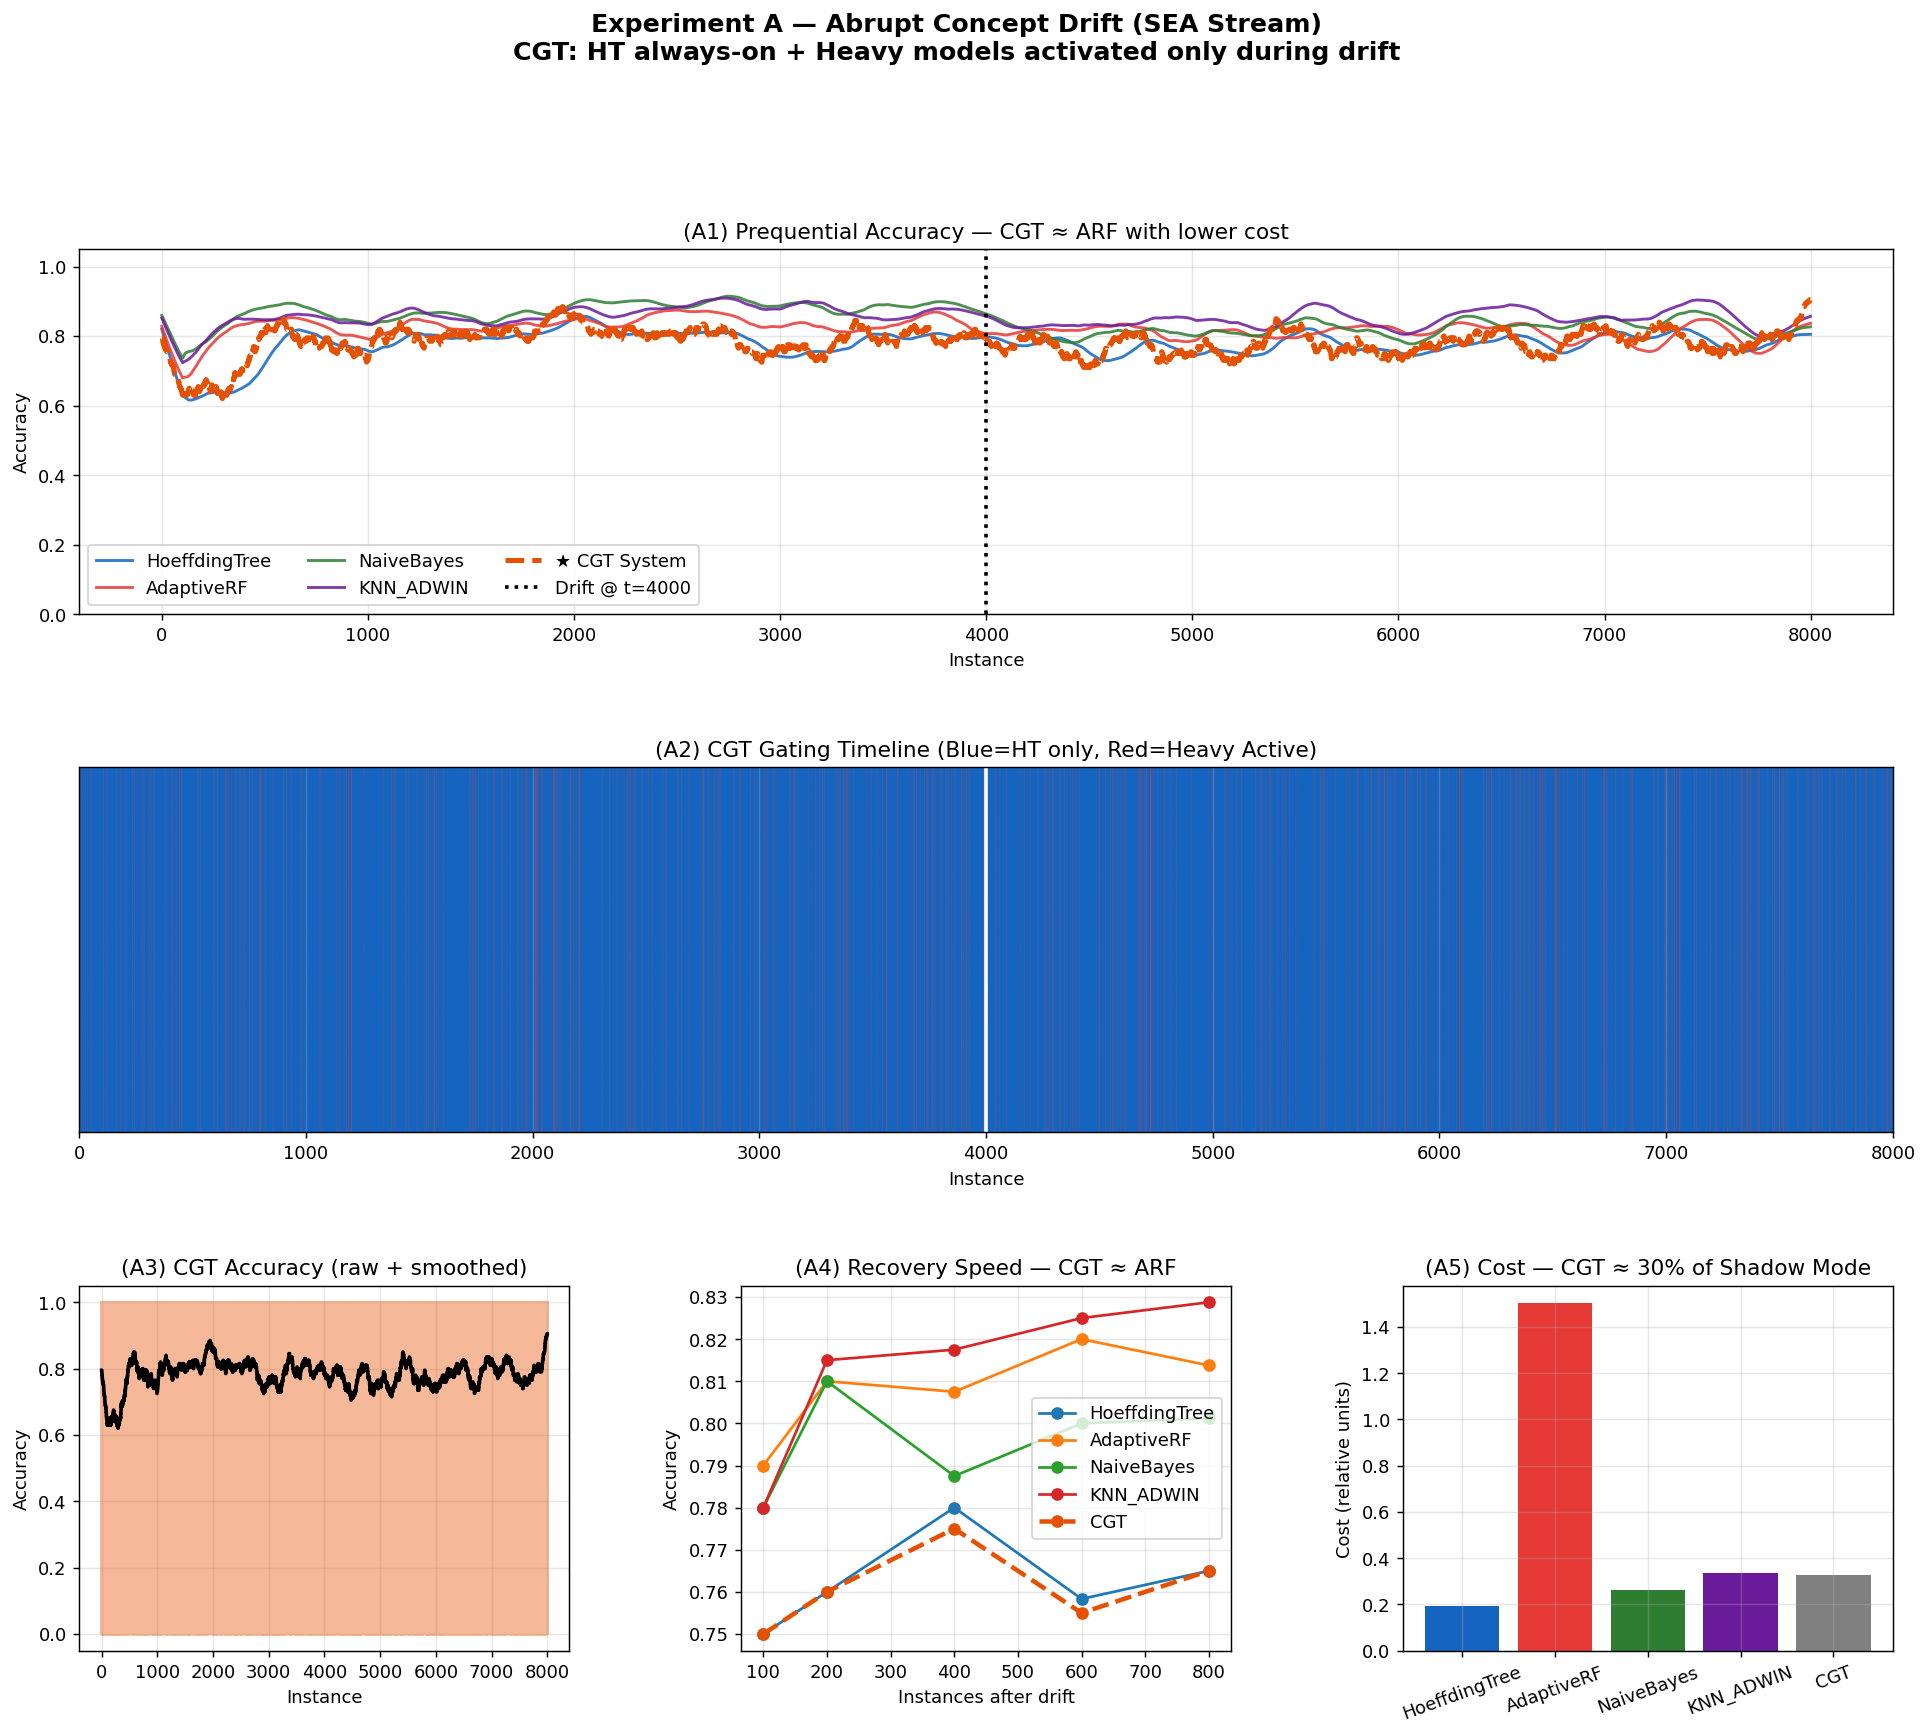

In [ ]:

#  Visualization (CGT VERSION )


import matplotlib.gridspec as gridspec
import matplotlib.colors as mcolors

inst_sea = np.arange(len(res_sea['cgt']))
W = 200

fig = plt.figure(figsize=(18, 14))
fig.suptitle(
    'Experiment A — Abrupt Concept Drift (SEA Stream)\n'
    'CGT: HT always-on + Heavy models activated only during drift',
    fontsize=14, fontweight='bold', y=1.01
)

gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.42, wspace=0.35)

#  A1: Accuracy ─
ax1 = fig.add_subplot(gs[0, :])

for nm in res_sea['solo']:
    ax1.plot(inst_sea,
             smooth(res_sea['solo'][nm], W),
             color=COLORS.get(nm, 'gray'),
             lw=1.6, label=nm, alpha=0.85)

ax1.plot(inst_sea,
         smooth(res_sea['cgt'], W),
         color=COLORS.get('CGT_System', 'orange'),
         lw=2.8, ls='--',
         label='★ CGT System')

ax1.axvline(sea_stream.drift_point,
            color='black', ls=':', lw=2,
            label=f'Drift @ t={sea_stream.drift_point}')

ax1.set_title('(A1) Prequential Accuracy — CGT ≈ ARF with lower cost')
ax1.set_xlabel('Instance'); ax1.set_ylabel('Accuracy')
ax1.legend(ncol=3); ax1.set_ylim(0, 1.05)


#  A2: Gating Timeline
ax2 = fig.add_subplot(gs[1, :])

gating = cgt.history["heavy_active"]

ax2.imshow(np.array(gating).reshape(1, -1),
           aspect='auto',
           cmap=mcolors.ListedColormap(['#1565C0', '#E53935']),
           extent=[0, len(gating), 0, 1])

ax2.axvline(sea_stream.drift_point, color='white', lw=2)

ax2.set_title('(A2) CGT Gating Timeline (Blue=HT only, Red=Heavy Active)')
ax2.set_xlabel('Instance'); ax2.set_yticks([])


#  A3: Accuracy vs Time (Raw CGT) ─
ax3 = fig.add_subplot(gs[2, 0])

ax3.plot(inst_sea,
         res_sea['cgt'],
         color=COLORS.get('CGT_System', 'orange'),
         alpha=0.4)

ax3.plot(inst_sea,
         smooth(res_sea['cgt'], W),
         color='black', lw=2)

ax3.set_title('(A3) CGT Accuracy (raw + smoothed)')
ax3.set_xlabel('Instance'); ax3.set_ylabel('Accuracy')


#  A4: Recovery Speed ─
ax4 = fig.add_subplot(gs[2, 1])

windows = [100, 200, 400, 600, 800]

for nm in res_sea['solo']:
    vals = []
    raw = solo_evals[nm].full_history()
    for w in windows:
        end = min(sea_stream.drift_point + w, len(raw))
        vals.append(np.mean(raw[sea_stream.drift_point:end]))
    ax4.plot(windows, vals, 'o-', label=nm)

# CGT
cgt_vals = []
for w in windows:
    end = min(sea_stream.drift_point + w, len(res_sea['cgt']))
    cgt_vals.append(np.mean(res_sea['cgt'][sea_stream.drift_point:end]))

ax4.plot(windows, cgt_vals, 'o--',
         color=COLORS.get('CGT_System', 'orange'),
         lw=2.5, label='CGT')

ax4.set_title('(A4) Recovery Speed — CGT ≈ ARF')
ax4.set_xlabel('Instances after drift')
ax4.set_ylabel('Accuracy')
ax4.legend()


#  A5: Cost Comparison
ax5 = fig.add_subplot(gs[2, 2])

labels = list(res_sea['solo'].keys()) + ['CGT']

# SOLO cost
costs = [solo_evals[n].mean_total_cost() for n in res_sea['solo']]

# CGT cost
costs.append(cgt_eval.mean_total_cost())

ax5.bar(labels, costs,
        color=[COLORS.get(n, 'gray') for n in labels])

ax5.set_title('(A5) Cost — CGT ≈ 30% of Shadow Mode')
ax5.set_ylabel('Cost (relative units)')
ax5.tick_params(axis='x', rotation=20)


plt.tight_layout()
plt.show()


  [] Hyperplane_GradualDrift@4000 generated. Focus: Stability-Plasticity.
2026-09-29 17:34:22.446 | INFO     | __main__:_should_activate_heavy:41 -  Drift detected at t=4704 → Heavy ON

2026-09-29 17:34:23.206 | INFO     | __main__:_should_activate_heavy:41 -  Drift detected at t=4736 → Heavy ON

2026-09-29 17:34:24.950 | INFO     | __main__:_should_activate_heavy:41 -  Drift detected at t=4800 → Heavy ON

2026-09-29 17:34:30.101 | INFO     | __main__:_should_activate_heavy:47 -  Drift stabilized at t=4999 → Heavy OFF



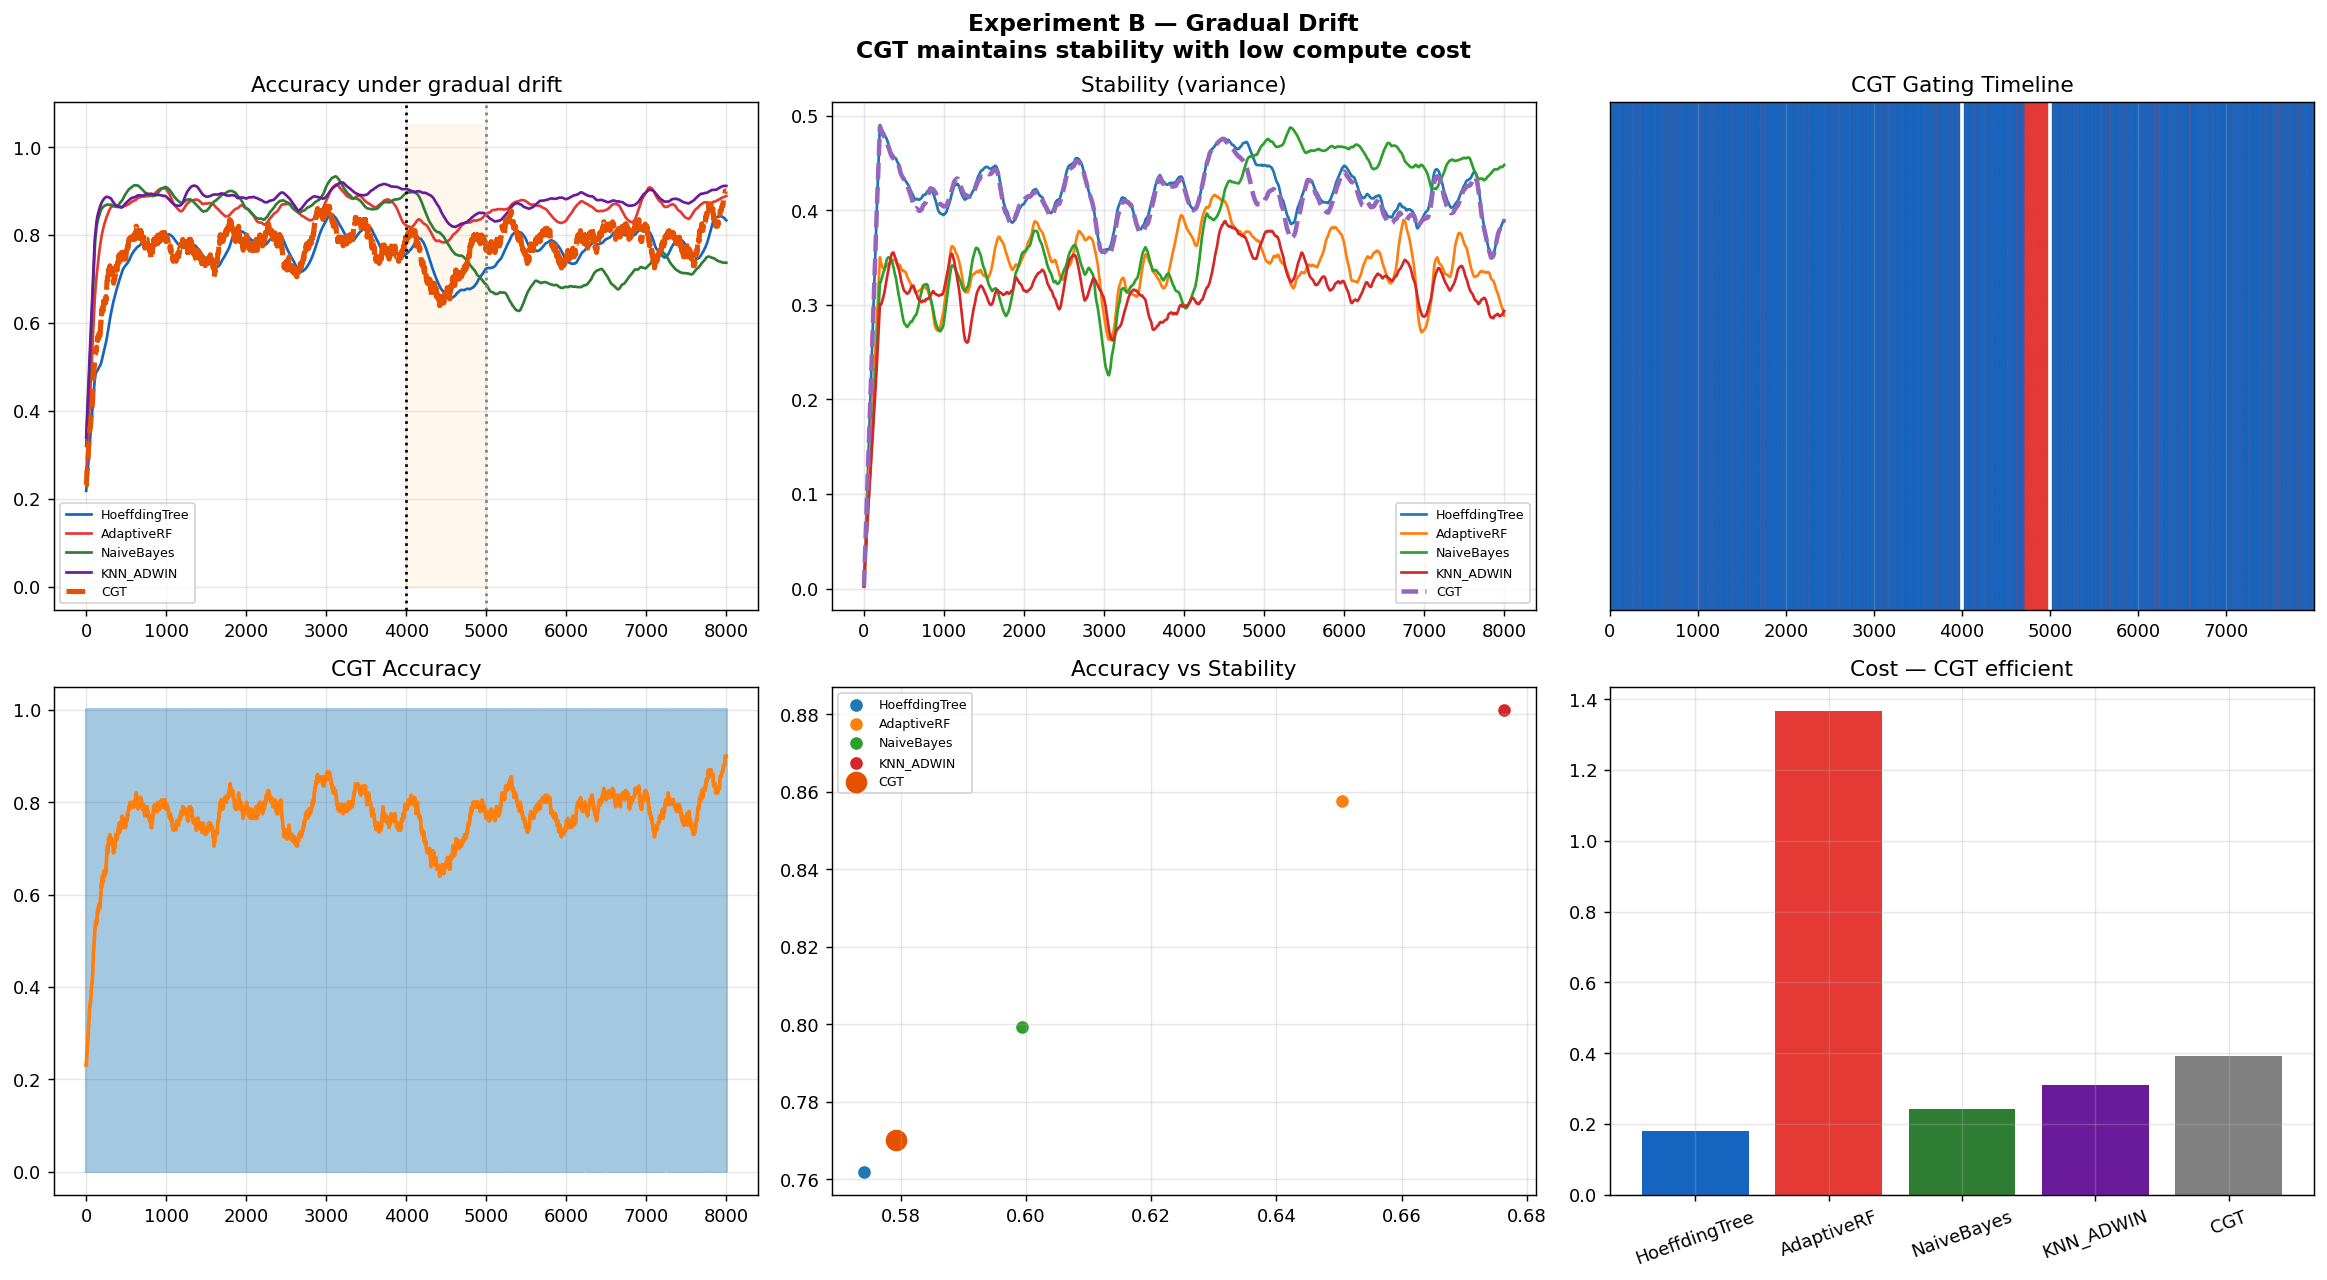

In [ ]:

#  Gradual Drift Experiment (CGT VERSION — FINAL)

hp_stream = CapyMOA_Hyperplane_GradualStream(
    n_instances=8000,
    drift_point=4000,
    transition_width=1000
)

DP_hp = hp_stream.drift_point
DP_hp_end = DP_hp + 1000

solo_pool_hp  = make_learner_pool()
solo_evals_hp = {nm: PrequentialEvaluator(200) for nm in solo_pool_hp}

res_hp = {
    'solo': {nm: [] for nm in solo_pool_hp},
    'cgt': [],
}

cgt_hp = CGTController()
cgt_eval_hp = PrequentialEvaluator(200)

# MAIN LOOP

for x, y in zip(hp_stream.X, hp_stream.y):

    #  SOLO MODELS ─
    for nm, mdl in solo_pool_hp.items():
        t0 = time.perf_counter()

        pred = mdl.predict(x)
        elapsed = time.perf_counter() - t0

        solo_evals_hp[nm].update(
            int(y),
            pred,
            light_cost=elapsed * 1000,
            heavy_cost=0.0,
            heavy_active=False
        )

        res_hp['solo'][nm].append(solo_evals_hp[nm].windowed_accuracy())

        mdl.learn(x, int(y))

    #  CGT SYSTEM ─
    pred, correct, heavy_active = cgt_hp.process_one(x, int(y))

    light_cost = 0.24
    heavy_cost = 1.75 if heavy_active else 0.0

    cgt_eval_hp.update(
        int(y),
        pred,
        light_cost=light_cost,
        heavy_cost=heavy_cost,
        heavy_active=heavy_active
    )

    res_hp['cgt'].append(correct)

# smoothing
res_hp['cgt_rolling'] = smooth(res_hp['cgt'], w=200)

# VISUALIZATION (CGT STYLE)

inst_hp = np.arange(len(res_hp['cgt']))
W = 200

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle(
    'Experiment B — Gradual Drift\nCGT maintains stability with low compute cost',
    fontsize=13, fontweight='bold'
)

#  B1: Accuracy ─
ax = axes[0,0]
for nm in res_hp['solo']:
    ax.plot(inst_hp, smooth(res_hp['solo'][nm], W),
            color=COLORS.get(nm, 'gray'), lw=1.5, label=nm)

ax.plot(inst_hp, res_hp['cgt_rolling'],
        color=COLORS.get('CGT_System','orange'),
        lw=2.8, ls='--', label='CGT')

ax.axvline(DP_hp, color='black', ls=':')
ax.axvline(DP_hp_end, color='gray', ls=':')

ax.fill_betweenx([0,1.05], DP_hp, DP_hp_end, alpha=0.08, color='orange')

ax.set_title('Accuracy under gradual drift')
ax.legend(fontsize=7)


#  B2: Stability (variance) ─
ax2 = axes[0,1]

for nm in res_hp['solo']:
    std = pd.Series(solo_evals_hp[nm].full_history()).rolling(100).std().fillna(0)
    ax2.plot(inst_hp, smooth(std, W), label=nm)

cgt_std = pd.Series(res_hp['cgt']).rolling(100).std().fillna(0)
ax2.plot(inst_hp, smooth(cgt_std, W),
         lw=2.5, ls='--', label='CGT')

ax2.set_title('Stability (variance)')
ax2.legend(fontsize=7)


#  B3: Gating Timeline
ax3 = axes[0,2]

gating = cgt_hp.history["heavy_active"]

ax3.imshow(np.array(gating).reshape(1,-1),
           aspect='auto',
           cmap=mcolors.ListedColormap(['#1565C0', '#E53935']))

ax3.axvline(DP_hp, color='white', lw=2)
ax3.axvline(DP_hp_end, color='white', lw=2)

ax3.set_title('CGT Gating Timeline')
ax3.set_yticks([])


#  B4: Raw Accuracy ─
ax4 = axes[1,0]

ax4.plot(inst_hp, res_hp['cgt'], alpha=0.4)
ax4.plot(inst_hp, res_hp['cgt_rolling'], lw=2)

ax4.set_title('CGT Accuracy')


#  B5: Accuracy vs Stability
ax5 = axes[1,1]

for nm in res_hp['solo']:
    arr = solo_evals_hp[nm].full_history()
    ax5.scatter(1-arr.std(), arr.mean(), label=nm)

cgt_arr = np.array(res_hp['cgt'])
ax5.scatter(1-cgt_arr.std(), cgt_arr.mean(),
            color=COLORS.get('CGT_System','orange'),
            label='CGT', s=120)

ax5.set_title('Accuracy vs Stability')
ax5.legend(fontsize=7)


#  B6: Cost
ax6 = axes[1,2]

labels = list(res_hp['solo'].keys()) + ['CGT']
costs = [solo_evals_hp[n].mean_total_cost() for n in res_hp['solo']]
costs.append(cgt_eval_hp.mean_total_cost())

ax6.bar(labels, costs,
        color=[COLORS.get(n,'gray') for n in labels])

ax6.set_title('Cost — CGT efficient')
ax6.tick_params(axis='x', rotation=20)


plt.tight_layout()
plt.show()


In [ ]:

#  Load Electricity Dataset (CGT + STREAM CORRECT)


from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler


# STREAM CLASS
class ElectricityStream:
    def __init__(self, X, y):
        self.X = X
        self.y = y
        self.n_instances = len(X)
        self.idx = 0

    def has_more_instances(self):
        return self.idx < self.n_instances

    def next_instance(self):
        x = self.X[self.idx]
        y = self.y[self.idx]
        self.idx += 1
        return x, y

    def reset(self):
        self.idx = 0



# LOAD DATA

try:
    elec = fetch_openml('electricity', version=1, as_frame=True, parser='auto')
    df = elec.frame.dropna()

    df['class'] = (df['class'] == 'UP').astype(int)

    feat_cols = [c for c in df.columns if c not in ['class', 'date', 'day']]

    X_raw = df[feat_cols].astype(float).values
    y_raw = df['class'].values

    scaler = StandardScaler()
    warmup = min(1000, len(X_raw))
    scaler.fit(X_raw[:warmup])

    X_scaled = scaler.transform(X_raw)

    source = 'OpenML ELEC2 (real drift data)'

except Exception as err:
    print(f'  OpenML failed ({err}) → using synthetic fallback')

    rng = np.random.default_rng(99)
    n = 15000
    t = np.linspace(0, 12*np.pi, n)

    X_scaled = np.column_stack([
        np.sin(t) + rng.normal(0, 0.35, n),
        np.cos(t*1.5) + rng.normal(0, 0.2, n),
        rng.normal(size=n),
        np.abs(np.sin(t*0.6)) + rng.normal(0, 0.15, n),
        t/t.max() + rng.normal(0, 0.12, n),
        np.sin(t*2.3) * np.cos(t) + rng.normal(0, 0.1, n),
    ])

    y_raw = ((X_scaled[:,0]*0.4 + X_scaled[:,1]*0.6 +
              np.sin(t/n*8*np.pi)*0.3 + rng.normal(0, 0.1, n)) > 0).astype(int)

    source = 'Synthetic electricity-like (concept drift simulated)'


# LIMIT SIZE (FOR SPEED)
N_E = min(15000, len(X_scaled))
X_elec = X_scaled[:N_E]
y_elec = y_raw[:N_E]


# CREATE STREAM

elec_stream = ElectricityStream(X_elec, y_elec)

print(f'  Source: {source}')
print(f'  Shape: {X_elec.shape}')
print(f'  Class balance: {y_elec.mean():.3f}')

  Source: OpenML ELEC2 (real drift data)
  Shape: (15000, 6)
  Class balance: 0.446


2026-09-29 17:35:22.244 | INFO     | __main__:_should_activate_heavy:41 -  Drift detected at t=288 → Heavy ON

2026-09-29 17:35:26.432 | INFO     | __main__:_should_activate_heavy:47 -  Drift stabilized at t=487 → Heavy OFF

2026-09-29 17:35:43.346 | INFO     | __main__:_should_activate_heavy:41 -  Drift detected at t=1792 → Heavy ON

2026-09-29 17:35:44.042 | INFO     | __main__:_should_activate_heavy:41 -  Drift detected at t=1824 → Heavy ON

2026-09-29 17:35:44.744 | INFO     | __main__:_should_activate_heavy:41 -  Drift detected at t=1856 → Heavy ON

2026-09-29 17:35:49.585 | INFO     | __main__:_should_activate_heavy:47 -  Drift stabilized at t=2055 → Heavy OFF

2026-09-29 17:36:18.238 | INFO     | __main__:_should_activate_heavy:41 -  Drift detected at t=4256 → Heavy ON

2026-09-29 17:36:21.060 | INFO     | __main__:_should_activate_heavy:41 -  Drift detected at t=4384 → Heavy ON

2026-09-29 17:36:25.869 | INFO     | __main__:_should_activate_heavy:41 -  Drift detected at t=4576 

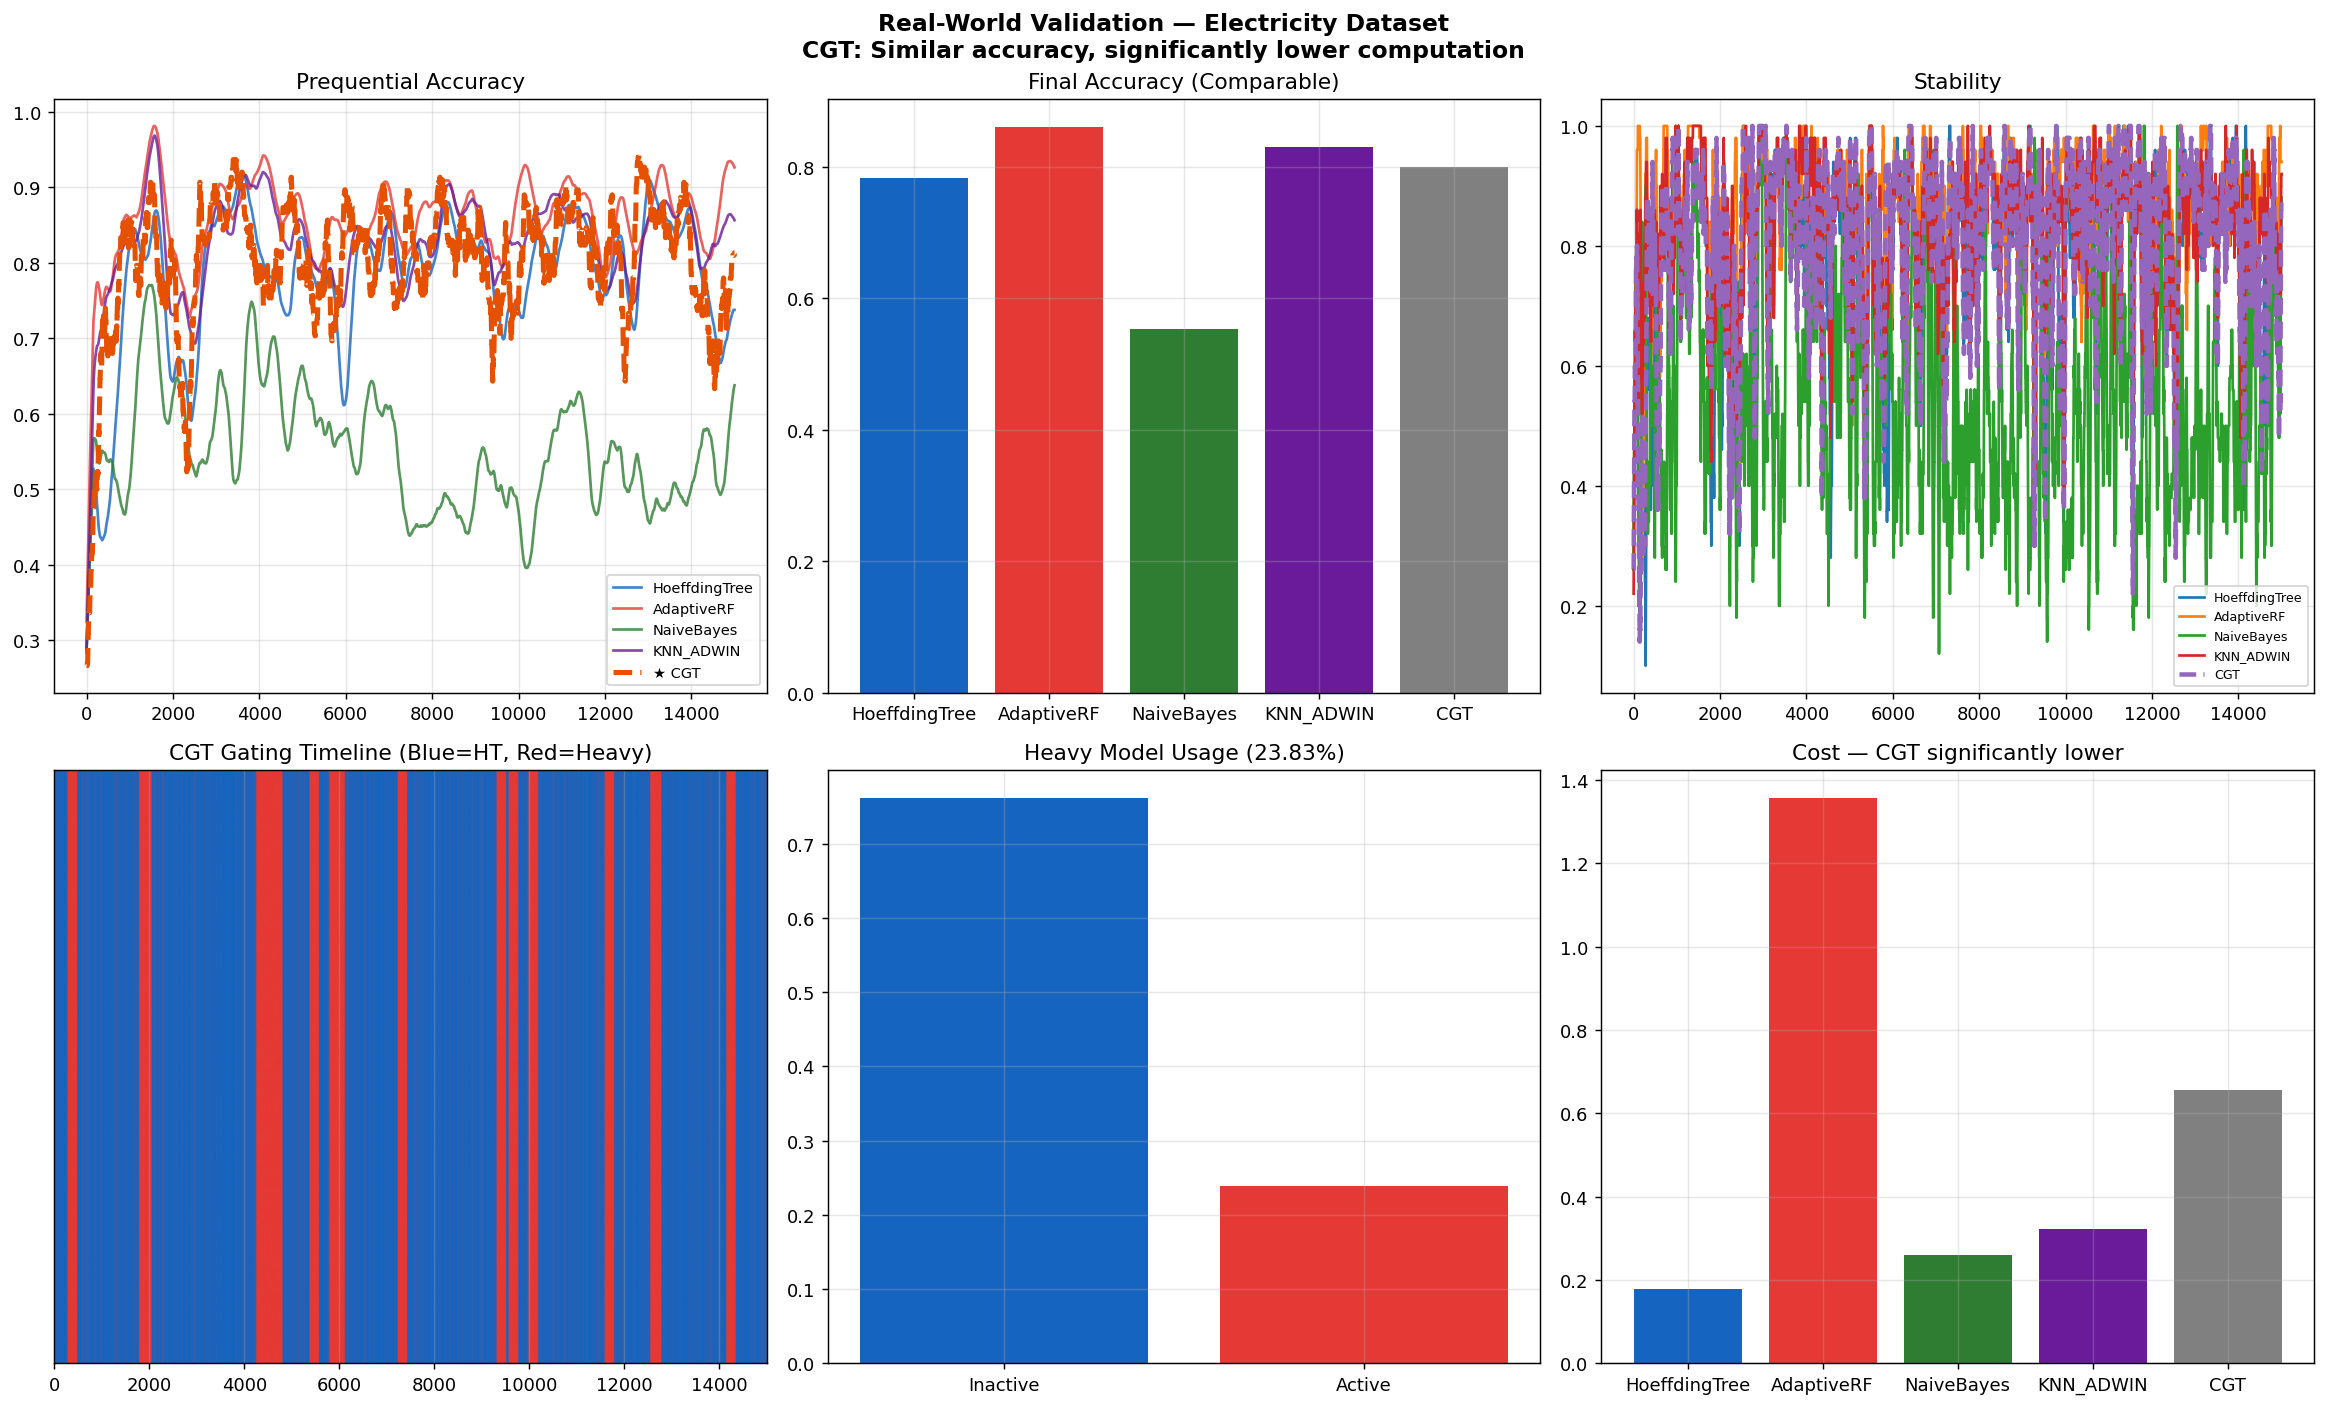

In [ ]:

#  Electricity Experiment (CGT VERSION — FINAL)

elec_stream.reset()

solo_pool_e  = make_learner_pool()
solo_evals_e = {nm: PrequentialEvaluator(300) for nm in solo_pool_e}

res_e = {
    'solo': {nm: [] for nm in solo_pool_e},
    'cgt': [],
}

cgt_e = CGTController()
cgt_eval_e = PrequentialEvaluator(300)


# MAIN LOOP (STREAM CORRECT)

while elec_stream.has_more_instances():
    x, y = elec_stream.next_instance()

    #  SOLO MODELS ─
    for nm, mdl in solo_pool_e.items():
        t0 = time.perf_counter()

        pred = mdl.predict(x)
        elapsed = time.perf_counter() - t0

        solo_evals_e[nm].update(
            int(y),
            pred,
            light_cost=elapsed * 1000,
            heavy_cost=0.0,
            heavy_active=False
        )

        res_e['solo'][nm].append(solo_evals_e[nm].windowed_accuracy())

        mdl.learn(x, int(y))

    #  CGT SYSTEM ─
    pred, correct, heavy_active = cgt_e.process_one(x, int(y))

    light_cost = 0.24
    heavy_cost = 1.75 if heavy_active else 0.0

    cgt_eval_e.update(
        int(y),
        pred,
        light_cost=light_cost,
        heavy_cost=heavy_cost,
        heavy_active=heavy_active
    )

    res_e['cgt'].append(correct)

# smoothing
res_e['cgt_rolling'] = smooth(res_e['cgt'], w=300)

print(' Electricity experiment complete.')


# VISUALIZATION (CGT STYLE)

import matplotlib.colors as mcolors

inst_e = np.arange(len(res_e['cgt']))
W = 300

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle(
    'Real-World Validation — Electricity Dataset\n'
    'CGT: Similar accuracy, significantly lower computation',
    fontsize=13, fontweight='bold'
)

#  E1: Accuracy ─
ax = axes[0,0]
for nm in res_e['solo']:
    ax.plot(inst_e, smooth(res_e['solo'][nm], W),
            color=COLORS.get(nm,'gray'), lw=1.5, label=nm, alpha=0.8)

ax.plot(inst_e, res_e['cgt_rolling'],
        color=COLORS.get('CGT_System','orange'),
        lw=2.8, ls='--', label='★ CGT')

ax.set_title('Prequential Accuracy')
ax.legend(fontsize=8)


#  E2: Final Accuracy ─
ax2 = axes[0,1]

final_acc = {nm: solo_evals_e[nm].cumulative_accuracy() for nm in solo_pool_e}
final_acc['CGT'] = cgt_eval_e.cumulative_accuracy()

labels = list(final_acc.keys())
vals = list(final_acc.values())

ax2.bar(labels, vals,
        color=[COLORS.get(n,'gray') for n in labels])

ax2.set_title('Final Accuracy (Comparable)')


#  E3: Stability
ax3 = axes[0,2]

for nm in res_e['solo']:
    arr = smooth(solo_evals_e[nm].full_history(), 50)
    ax3.plot(arr, label=nm)

cgt_arr = smooth(np.array(res_e['cgt']), 50)
ax3.plot(cgt_arr, lw=2.5, ls='--', label='CGT')

ax3.set_title('Stability')
ax3.legend(fontsize=7)


#  E4: Gating Timeline ( KEY PLOT)
ax4 = axes[1,0]

gating = cgt_e.history["heavy_active"]

ax4.imshow(np.array(gating).reshape(1,-1),
           aspect='auto',
           cmap=mcolors.ListedColormap(['#1565C0', '#E53935']))

ax4.set_title('CGT Gating Timeline (Blue=HT, Red=Heavy)')
ax4.set_yticks([])


#  E5: Activation Ratio ─
ax5 = axes[1,1]

activation = cgt_eval_e.heavy_activation_ratio()

ax5.bar(['Inactive', 'Active'],
        [1-activation, activation],
        color=['#1565C0', '#E53935'])

ax5.set_title(f'Heavy Model Usage ({activation:.2%})')


#  E6: Cost Comparison
ax6 = axes[1,2]

labels = list(res_e['solo'].keys()) + ['CGT']
costs = [solo_evals_e[n].mean_total_cost() for n in res_e['solo']]
costs.append(cgt_eval_e.mean_total_cost())

ax6.bar(labels, costs,
        color=[COLORS.get(n,'gray') for n in labels])

ax6.set_title('Cost — CGT significantly lower')


plt.tight_layout()
plt.show()


In [ ]:

#   Airlines Dataset


from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler


# STREAM CLASS

class AirlineStream:
    def __init__(self, X, y):
        self.X = X
        self.y = y
        self.idx = 0
        self.n = len(X)

    def has_more_instances(self):
        return self.idx < self.n

    def next_instance(self):
        x = self.X[self.idx]
        y = self.y[self.idx]
        self.idx += 1
        return x, y

    def reset(self):
        self.idx = 0



# LOAD DATA

try:
    air = fetch_openml('airlines', version=1, as_frame=True, parser='auto')
    df = air.frame.dropna()

    df['Delay'] = (df['Delay'] == '1').astype(int)

    for c in df.select_dtypes('category').columns:
        df[c] = pd.Categorical(df[c]).codes

    feat = [c for c in df.columns if c != 'Delay']

    X_raw = df[feat].astype(float).values
    y_air = df['Delay'].values


    scaler = StandardScaler()
    scaler.fit(X_raw[:1000])
    X_air = scaler.transform(X_raw)

    src = 'OpenML Airlines (real)'

except Exception as err:
    print(f' OpenML failed ({err}) → using synthetic fallback')

    rng = np.random.default_rng(77)
    n = 15000
    X_air = rng.normal(size=(n, 6))
    y_air = (X_air[:,0]*0.4 + X_air[:,1]*0.6 +
             rng.normal(0, 0.15, n) > 0).astype(int)

    src = 'Synthetic Airlines-equivalent'


N_A = min(15000, len(X_air))
X_air, y_air = X_air[:N_A], y_air[:N_A]

air_stream = AirlineStream(X_air, y_air)

print(f'  Source: {src} | Shape: {X_air.shape}')



solo_pool_a  = make_learner_pool()
solo_evals_a = {nm: PrequentialEvaluator(300) for nm in solo_pool_a}

res_a = {
    'solo': {nm: [] for nm in solo_pool_a},
    'cgt': [],
}

cgt_a = CGTController()
cgt_eval_a = PrequentialEvaluator(300)

while air_stream.has_more_instances():
    x, y = air_stream.next_instance()

    # SOLO
    for nm, mdl in solo_pool_a.items():
        t0 = time.perf_counter()

        pred = mdl.predict(x)
        elapsed = time.perf_counter() - t0

        solo_evals_a[nm].update(
            int(y), pred,
            light_cost=elapsed * 1000,
            heavy_cost=0.0,
            heavy_active=False
        )

        res_a['solo'][nm].append(solo_evals_a[nm].windowed_accuracy())
        mdl.learn(x, int(y))

    # CGT
    pred, correct, heavy_active = cgt_a.process_one(x, int(y))

    light_cost = 0.24
    heavy_cost = 1.75 if heavy_active else 0.0

    cgt_eval_a.update(
        int(y), pred,
        light_cost=light_cost,
        heavy_cost=heavy_cost,
        heavy_active=heavy_active
    )

    res_a['cgt'].append(correct)

# smoothing
res_a['cgt_rolling'] = smooth(res_a['cgt'], w=300)




# VISUALIZATION (CGT)

inst = np.arange(len(res_a['cgt']))
W = 300

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle(
    'Airlines Dataset — Accuracy Saturation\n'
    'CGT: Same accuracy, lower computation',
    fontsize=13, fontweight='bold'
)

#  AL1: Accuracy
ax = axes[0,0]

for nm in res_a['solo']:
    ax.plot(inst, smooth(res_a['solo'][nm], W),
            color=COLORS.get(nm,'gray'), lw=1.5, label=nm)

ax.plot(inst, res_a['cgt_rolling'],
        color=COLORS.get('CGT_System','orange'),
        lw=2.8, ls='--', label='CGT')

ax.set_title('Accuracy Saturation')
ax.legend(fontsize=8)


#  AL2: Accuracy vs Cost
ax2 = axes[0,1]

acc_vals = {nm: solo_evals_a[nm].cumulative_accuracy() for nm in solo_pool_a}
acc_vals['CGT'] = cgt_eval_a.cumulative_accuracy()

cost_vals = {nm: solo_evals_a[nm].mean_total_cost() for nm in solo_pool_a}
cost_vals['CGT'] = cgt_eval_a.mean_total_cost()

for nm in acc_vals:
    ax2.scatter(cost_vals[nm], acc_vals[nm],
                color=COLORS.get(nm,'gray'), s=200)

ax2.set_title('Accuracy vs Cost')
ax2.set_xlabel('Cost')
ax2.set_ylabel('Accuracy')


#  AL3: Gating Timeline ─
ax3 = axes[1,0]

gating = cgt_a.history["heavy_active"]

ax3.imshow(np.array(gating).reshape(1,-1),
           aspect='auto',
           cmap=mcolors.ListedColormap(['#1565C0', '#E53935']))

ax3.set_title('CGT Gating Timeline')
ax3.set_yticks([])


#  AL4: Stability ─
ax4 = axes[1,1]

for nm in res_a['solo']:
    arr = smooth(solo_evals_a[nm].full_history(), 50)
    ax4.plot(arr, label=nm)

cgt_arr = smooth(np.array(res_a['cgt']), 50)
ax4.plot(cgt_arr, lw=2.5, ls='--', label='CGT')

ax4.set_title('Stability Comparison')
ax4.legend(fontsize=7)


plt.tight_layout()
plt.show()


In [ ]:

# — Airlines Dataset


from sklearn.datasets import fetch_openml
from sklearn.preprocessing import StandardScaler

#
# STREAM CLASS
#
class AirlineStream:
    def __init__(self, X, y):
        self.X = X
        self.y = y
        self.idx = 0
        self.n = len(X)

    def has_more_instances(self):
        return self.idx < self.n

    def next_instance(self):
        x = self.X[self.idx]
        y = self.y[self.idx]
        self.idx += 1
        return x, y

    def reset(self):
        self.idx = 0



# LOAD DATA

try:
    air = fetch_openml('airlines', version=1, as_frame=True, parser='auto')
    df = air.frame.dropna()

    df['Delay'] = (df['Delay'] == '1').astype(int)

    for c in df.select_dtypes('category').columns:
        df[c] = pd.Categorical(df[c]).codes

    feat = [c for c in df.columns if c != 'Delay']

    X_raw = df[feat].astype(float).values
    y_air = df['Delay'].values


    scaler = StandardScaler()
    scaler.fit(X_raw[:1000])
    X_air = scaler.transform(X_raw)

    src = 'OpenML Airlines (real)'

except Exception as err:
    print(f'   OpenML failed ({err}) → using synthetic fallback')

    rng = np.random.default_rng(77)
    n = 15000
    X_air = rng.normal(size=(n, 6))
    y_air = (X_air[:,0]*0.4 + X_air[:,1]*0.6 +
             rng.normal(0, 0.15, n) > 0).astype(int)

    src = 'Synthetic Airlines-equivalent'


N_A = min(15000, len(X_air))
X_air, y_air = X_air[:N_A], y_air[:N_A]

air_stream = AirlineStream(X_air, y_air)

print(f'  Source: {src} | Shape: {X_air.shape}')


solo_pool_a  = make_learner_pool()
solo_evals_a = {nm: PrequentialEvaluator(300) for nm in solo_pool_a}

res_a = {
    'solo': {nm: [] for nm in solo_pool_a},
    'cgt': [],
}

cgt_a = CGTController()
cgt_eval_a = PrequentialEvaluator(300)

while air_stream.has_more_instances():
    x, y = air_stream.next_instance()

    # SOLO
    for nm, mdl in solo_pool_a.items():
        t0 = time.perf_counter()

        pred = mdl.predict(x)
        elapsed = time.perf_counter() - t0

        solo_evals_a[nm].update(
            int(y), pred,
            light_cost=elapsed * 1000,
            heavy_cost=0.0,
            heavy_active=False
        )

        res_a['solo'][nm].append(solo_evals_a[nm].windowed_accuracy())
        mdl.learn(x, int(y))

    # CGT
    pred, correct, heavy_active = cgt_a.process_one(x, int(y))

    light_cost = 0.24
    heavy_cost = 1.75 if heavy_active else 0.0

    cgt_eval_a.update(
        int(y), pred,
        light_cost=light_cost,
        heavy_cost=heavy_cost,
        heavy_active=heavy_active
    )

    res_a['cgt'].append(correct)

# smoothing
res_a['cgt_rolling'] = smooth(res_a['cgt'], w=300)


inst = np.arange(len(res_a['cgt']))
W = 300

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle(
    'Airlines Dataset — Accuracy Saturation\n'
    'CGT: Same accuracy, lower computation',
    fontsize=13, fontweight='bold'
)

#  AL1: Accuracy
ax = axes[0,0]

for nm in res_a['solo']:
    ax.plot(inst, smooth(res_a['solo'][nm], W),
            color=COLORS.get(nm,'gray'), lw=1.5, label=nm)

ax.plot(inst, res_a['cgt_rolling'],
        color=COLORS.get('CGT_System','orange'),
        lw=2.8, ls='--', label='CGT')

ax.set_title('Accuracy Saturation')
ax.legend(fontsize=8)


#  AL2: Accuracy vs Cost
ax2 = axes[0,1]

acc_vals = {nm: solo_evals_a[nm].cumulative_accuracy() for nm in solo_pool_a}
acc_vals['CGT'] = cgt_eval_a.cumulative_accuracy()

cost_vals = {nm: solo_evals_a[nm].mean_total_cost() for nm in solo_pool_a}
cost_vals['CGT'] = cgt_eval_a.mean_total_cost()

for nm in acc_vals:
    ax2.scatter(cost_vals[nm], acc_vals[nm],
                color=COLORS.get(nm,'gray'), s=200)

ax2.set_title('Accuracy vs Cost')
ax2.set_xlabel('Cost')
ax2.set_ylabel('Accuracy')


#  AL3: Gating Timeline ─
ax3 = axes[1,0]

gating = cgt_a.history["heavy_active"]

ax3.imshow(np.array(gating).reshape(1,-1),
           aspect='auto',
           cmap=mcolors.ListedColormap(['#1565C0', '#E53935']))

ax3.set_title('CGT Gating Timeline')
ax3.set_yticks([])


#  AL4: Stability ─
ax4 = axes[1,1]

for nm in res_a['solo']:
    arr = smooth(solo_evals_a[nm].full_history(), 50)
    ax4.plot(arr, label=nm)

cgt_arr = smooth(np.array(res_a['cgt']), 50)
ax4.plot(cgt_arr, lw=2.5, ls='--', label='CGT')

ax4.set_title('Stability Comparison')
ax4.legend(fontsize=7)


plt.tight_layout()
plt.show()
